In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
W = np.random.normal(0, 1, (1000,))
X = W + np.random.normal(0, 1, (1000,)) 
Z = np.random.normal(0, 1, (1000,)) 
Y = X + Z + W + np.random.normal(0, 1, (1000,))

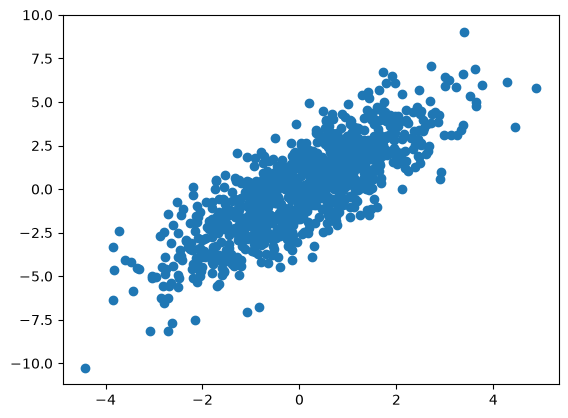

In [3]:
plt.scatter(X,Y)

Which is closest to the correlation of X with the error term in the equation for Y? 
<br> What is the error term?

In [4]:
x = pd.Series(X)
w = pd.Series(W)
z = pd.Series(Z)
y = pd.Series(Y)


x.corr(y)

np.float64(0.80249991268405)

## Question 1: Correlation of X with the error term

```
Question 1: Correlation of X with the error term in the equation for Y.

The data generating process is:
    W = noise
    X = W + noise
    Z = noise
    Y = X + Z + W + e      <- e is "the error term"

Intuition:
    The error term e is only the last np.random.normal(...) in Y's equation.
    It is drawn fresh, completely independently of W, X and Z.
    Independent variables have zero correlation, so corr(X, e) should be ~0.

    Because the model includes every true cause of Y (X, Z and W), nothing
    that drives X is hiding inside the error. That is exactly the condition
    linear regression needs for an unbiased coefficient on X.
```

In [5]:
import numpy as np

np.random.seed(0)
n = 100_000  # larger than the homework's 1000 so the estimate is less noisy

W = np.random.normal(0, 1, n)
X = W + np.random.normal(0, 1, n)
Z = np.random.normal(0, 1, n)
e = np.random.normal(0, 1, n)   # the error term, kept separately so we can inspect it
Y = X + Z + W + e

print("corr(X, error) =", round(np.corrcoef(X, e)[0, 1], 3))
print("Expected: about 0, because e was generated independently of X.")

corr(X, error) = 0.001
Expected: about 0, because e was generated independently of X.


## Question 2: Omitted variable (W in the error)

```
Question 2: What if we write Y as depending on X and Z only?

Same data as Question 1, but now we leave W out of the model:
    Y = X + Z + (W + e)
                 ^^^^^^^ everything not in the model becomes "the error"

Intuition:
    X was built from W (X = W + u). The error now also contains W.
    So X and the error share a common ingredient, W, and are correlated.
    This is omitted-variable bias: the regression would wrongly credit X with
    some of W's effect on Y.

The math (all noise terms have variance 1 and are independent):
    Cov(X, error) = Cov(W + u, W + e) = Var(W)       = 1
    Var(X)        = Var(W) + Var(u)                  = 2
    Var(error)    = Var(W) + Var(e)                  = 2
    corr          = 1 / sqrt(2 * 2)                  = 0.5
```

In [6]:
import numpy as np

np.random.seed(0)
n = 100_000

W = np.random.normal(0, 1, n)
u = np.random.normal(0, 1, n)
X = W + u
Z = np.random.normal(0, 1, n)
e = np.random.normal(0, 1, n)
Y = X + Z + W + e

error_without_W = W + e   # what the error looks like when W is omitted

print("corr(X, W + e) =", round(np.corrcoef(X, error_without_W)[0, 1], 3))
print("Theory:        =", round(1 / np.sqrt(2 * 2), 3))

# Bonus: see the bias directly. Regress Y on X and Z with and without W.
def ols(y, *cols):
    A = np.column_stack([np.ones(len(y)), *cols])
    return np.linalg.lstsq(A, y, rcond=None)[0]

print("\nX coefficient with W in the model:   ", round(ols(Y, X, Z, W)[1], 3), "(true value is 1)")
print("X coefficient with W left out:        ", round(ols(Y, X, Z)[1], 3), "(biased upward by W)")

corr(X, W + e) = 0.499
Theory:        = 0.5

X coefficient with W in the model:    0.998 (true value is 1)
X coefficient with W left out:         1.5 (biased upward by W)


## Question 3: Controlling for W with narrow windows

```
Question 3: Control for W by regressing Y on X and Z at W = -1, 0 and 1.

The problem: W is continuous, so almost no rows have W exactly equal to -1.
If you filter on W == -1 you get zero or one data point.

The fix: use a narrow WINDOW around each value, e.g. rows where |W - (-1)| < 0.1.
Inside that window W is roughly constant, so it is "held fixed" and cannot
confound the X -> Y relationship. Then run an ordinary regression of Y on X
and Z using only those rows.

Intuition for the answer:
    If the X coefficient changes as W changes, the effect of X DEPENDS on W.
    That means the data was generated with an interaction term, something like
        Y = ... + b * X * W + ...
    In homework_7.1.csv the X coefficient goes UP as W goes from -1 to 1,
    so the answer is "increasing".

Trade-off with the window width:
    Too narrow  -> few rows, noisy coefficients.
    Too wide    -> W is no longer close to constant, so the control is weaker.
    Print n for each window and widen it if a window has too few rows.
```

In [7]:
import numpy as np
import pandas as pd

df = pd.read_csv("homework_7.1.csv")
WINDOW = 0.1

def ols(y, *cols):
    """Ordinary least squares with an intercept. Returns [intercept, coef1, coef2, ...]."""
    A = np.column_stack([np.ones(len(y)), *cols])
    return np.linalg.lstsq(A, y, rcond=None)[0]

for w in [-1, 0, 1]:
    subset = df[(df["W"] - w).abs() < WINDOW]          # rows where W is close to w
    b = ols(subset["Y"], subset["X"], subset["Z"])
    print(f"W ≈ {w:+d}:  X coef = {b[1]:.3f}   Z coef = {b[2]:.3f}   (n = {len(subset)})")

print("\nIf the X coefficient rises as W rises, the answer is 'increasing'.")

W ≈ -1:  X coef = 0.858   Z coef = -0.587   (n = 488)
W ≈ +0:  X coef = 1.383   Z coef = -0.565   (n = 780)
W ≈ +1:  X coef = 1.958   Z coef = -0.568   (n = 455)

If the X coefficient rises as W rises, the answer is 'increasing'.


## Question 4: Autocorrelated errors and standard errors

```
Question 4: What happens to standard errors when the errors are autocorrelated?

make_error() creates errors where each value carries over a fraction
corr_const of the previous value:
    prev = corr_const * prev + (1 - corr_const) * new_noise
Higher corr_const -> neighbouring errors are more alike (stronger autocorrelation).

We use this error for both the treatment X and the outcome Y, run OLS many
times, and compare two numbers:
    (i)  SD of the X coefficient across trials -> how much the estimate REALLY varies
    (ii) Mean standard error reported by OLS    -> how much OLS THINKS it varies

Intuition:
    The OLS standard-error formula assumes every observation is independent.
    With autocorrelation, neighbouring rows are near-copies of each other, so
    200 rows carry much less information than 200 independent rows would.
    OLS doesn't know that, so it keeps reporting a small SE. Meanwhile the real
    spread of the estimate (i) grows. So the ratio (i) / (ii) increases as
    corr_const increases: OLS becomes overconfident.

    (The fix in practice is robust "HAC" / Newey-West standard errors.)
```

In [8]:
import numpy as np

np.random.seed(0)

def make_error(corr_const, num):
    err = []
    prev = np.random.normal(0, 1)
    for n in range(num):
        prev = corr_const * prev + (1 - corr_const) * np.random.normal(0, 1)
        err.append(prev)
    return np.array(err)

def ols_with_se(y, x):
    """OLS of y on x WITH an intercept (per the hint). Returns slope and its standard error."""
    A = np.column_stack([np.ones(len(x)), x])         # column of 1s = intercept
    beta = np.linalg.lstsq(A, y, rcond=None)[0]
    resid = y - A @ beta
    sigma2 = resid @ resid / (len(y) - A.shape[1])    # estimated error variance
    cov = sigma2 * np.linalg.inv(A.T @ A)             # classic OLS formula (assumes independence)
    return beta[1], np.sqrt(cov[1, 1])

N_OBS, N_TRIALS, TRUE_EFFECT = 200, 1000, 2.0

print(f"{'corr_const':>10} | {'(i) SD of coef':>14} | {'(ii) mean SE':>12} | {'ratio (i)/(ii)':>14}")
for corr_const in [0.2, 0.5, 0.8]:
    coefs, ses = [], []
    for _ in range(N_TRIALS):
        X = make_error(corr_const, N_OBS)                          # (a) treatment uses make_error
        Y = TRUE_EFFECT * X + make_error(corr_const, N_OBS)        # (b) outcome error uses make_error
        coef, se = ols_with_se(Y, X)
        coefs.append(coef)
        ses.append(se)
    sd_i, se_ii = np.std(coefs), np.mean(ses)
    print(f"{corr_const:>10} | {sd_i:>14.4f} | {se_ii:>12.4f} | {sd_i / se_ii:>14.2f}")

print("\nThe ratio rises with corr_const: OLS standard errors understate the true uncertainty.")

corr_const | (i) SD of coef | (ii) mean SE | ratio (i)/(ii)
       0.2 |         0.0750 |       0.0709 |           1.06
       0.5 |         0.0905 |       0.0712 |           1.27
       0.8 |         0.1694 |       0.0708 |           2.39

The ratio rises with corr_const: OLS standard errors understate the true uncertainty.
